# Cafe Sales: Exploratory Data Analysis (EDA)
**DecodeLabs Data Analytics, Project 2** | Input: the audited dataset from Project 1 (`cafe_sales_clean.csv`)

**Scenario.** A cafe owner has a year of sales (10,000 transactions). Before building any dashboard or forecast, the owner wants to understand the data:
1. Which items drive sales and revenue?
2. Is there a difference between in-store and takeaway customers?
3. Are there trends over the year (seasonality, busy days)?
4. Are there unusual values (outliers) we should worry about?

**Workflow (IPO framework from the project deck):** Input (clean data) -> Process (statistics, outliers, trends, correlation) -> Output (key observations).

| Step | What we do | Deck requirement |
|---|---|---|
| 1 | Set up and load the data | Input |
| 2 | Check data quality and define what to exclude | Input |
| 3 | Basic statistics (mean, median, count) | Requirement 1 |
| 4 | Distributions: look at the shape | Requirement 2 |
| 5 | Outliers (IQR vs Z-score) | Requirement 2 |
| 6 | Categories: items, location, payment | Requirement 2 |
| 7 | Trends over time | Requirement 2 |
| 8 | Correlation | Extra credit |
| 9 | Key observations (the "So what?" test) | Requirement 3 |
| 10 | Save outputs | Portfolio |

**To run:** `pip install pandas numpy matplotlib seaborn scipy jupyter`, put `cafe_sales_clean.csv` next to this notebook, then run all cells.

## Step 1: Set up and load the data

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.2f}".format)

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
TAB_DIR = Path("tables");  TAB_DIR.mkdir(exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
df = pd.read_csv("cafe_sales_clean.csv", parse_dates=["Transaction Date"])
NUM_COLS = ["Quantity", "Price Per Unit", "Total Spent"]
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
df.head()

Rows: 10,000 | Columns: 8


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.00,4.00,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.00,12.00,Cash,In-Store,2023-05-16
2,TXN_4271903,Cookie,4,1.00,4.00,Credit Card,In-Store,2023-07-19
3,TXN_7034554,Salad,2,5.00,10.00,Unknown,Unknown,2023-04-27
4,TXN_3160411,Coffee,2,2.00,4.00,Digital Wallet,In-Store,2023-06-11


## Step 2: Data quality check (what can we trust?)
The data was cleaned in Project 1, but a few gaps were deliberately left unfilled rather than guessed. EDA starts by being clear about them, so we know what to exclude from each calculation.

In [3]:
quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": df.isna().mean() * 100,
})
quality

,missing,missing_%
Transaction ID,0,0.00
Item,0,0.00
Quantity,0,0.00
Price Per Unit,6,0.06
Total Spent,3,0.03
Payment Method,0,0.00
Location,0,0.00
Transaction Date,460,4.60


In [4]:
# Categories labelled "Unknown" in Project 1 (kept as a category, not guessed)
for col in ["Item", "Payment Method", "Location"]:
    n = (df[col] == "Unknown").sum()
    print(f"{col:15s} 'Unknown': {n:5,} rows ({n/len(df):.1%})")

print(f"\nDuplicate Transaction IDs: {df['Transaction ID'].duplicated().sum()}")
print(f"Date range: {df['Transaction Date'].min().date()} to {df['Transaction Date'].max().date()}")

Item            'Unknown':   480 rows (4.8%)
Payment Method  'Unknown': 3,178 rows (31.8%)
Location        'Unknown': 3,961 rows (39.6%)

Duplicate Transaction IDs: 0
Date range: 2023-01-01 to 2023-12-31


In [5]:
# Analysis subsets: each question uses only the rows it can trust
dated = df.dropna(subset=["Transaction Date"]).copy()              # for trend analysis
known_item = df[df["Item"] != "Unknown"]                           # for item comparisons
known_loc = df[df["Location"] != "Unknown"]                        # for in-store vs takeaway
known_pay = df[df["Payment Method"] != "Unknown"]                  # for payment comparisons

print(f"Rows usable for trends (have a date):      {len(dated):,}")
print(f"Rows usable for item comparison:           {len(known_item):,}")
print(f"Rows usable for location comparison:       {len(known_loc):,}")
print(f"Rows usable for payment comparison:        {len(known_pay):,}")

Rows usable for trends (have a date):      9,540
Rows usable for item comparison:           9,520
Rows usable for location comparison:       6,039
Rows usable for payment comparison:        6,822


## Step 3: Basic statistics (mean, median, count)
Rule from the deck: the **median** is robust to anomalies and is the safer centre for skewed data; the **mean** is only reliable for symmetric data. Comparing them is a quick skew check.

In [6]:
summary = df[NUM_COLS].agg(["count", "mean", "median", "std", "min", "max"]).T
summary["mean - median"] = summary["mean"] - summary["median"]
summary["skewness"] = df[NUM_COLS].skew()
summary

,count,mean,median,std,min,max,mean - median,skewness
Quantity,"10,000.00",3.02,3.00,1.42,1.00,5.00,0.02,-0.01
Price Per Unit,"9,994.00",2.95,3.00,1.28,1.00,5.00,-0.05,0.01
Total Spent,"9,997.00",8.93,8.00,6.00,1.00,25.00,0.93,0.82


In [7]:
# Five-number summary: min, Q1, median, Q3, max
df[NUM_COLS].describe().loc[["min", "25%", "50%", "75%", "max"]].T

,min,25%,50%,75%,max
Quantity,1.00,2.00,3.00,4.00,5.00
Price Per Unit,1.00,2.00,3.00,4.00,5.00
Total Spent,1.00,4.00,8.00,12.00,25.00


In [8]:
# Counts for categorical columns
for col in ["Item", "Location", "Payment Method"]:
    print(df[col].value_counts().to_frame("transactions"), "\n")

          transactions
Item                  
Coffee            1291
Salad             1272
Cookie            1213
Tea               1207
Juice             1171
Cake              1139
Sandwich          1131
Smoothie          1096
Unknown            480 

          transactions
Location              
Unknown           3961
Takeaway          3022
In-Store          3017 

                transactions
Payment Method              
Unknown                 3178
Digital Wallet          2291
Credit Card             2273
Cash                    2258 



## Step 4: Distributions (what is the shape of the evidence?)
Quantity and price take a small set of fixed values, so we plot them as counts. Total Spent is Quantity x Price, so its shape is worth a closer look.

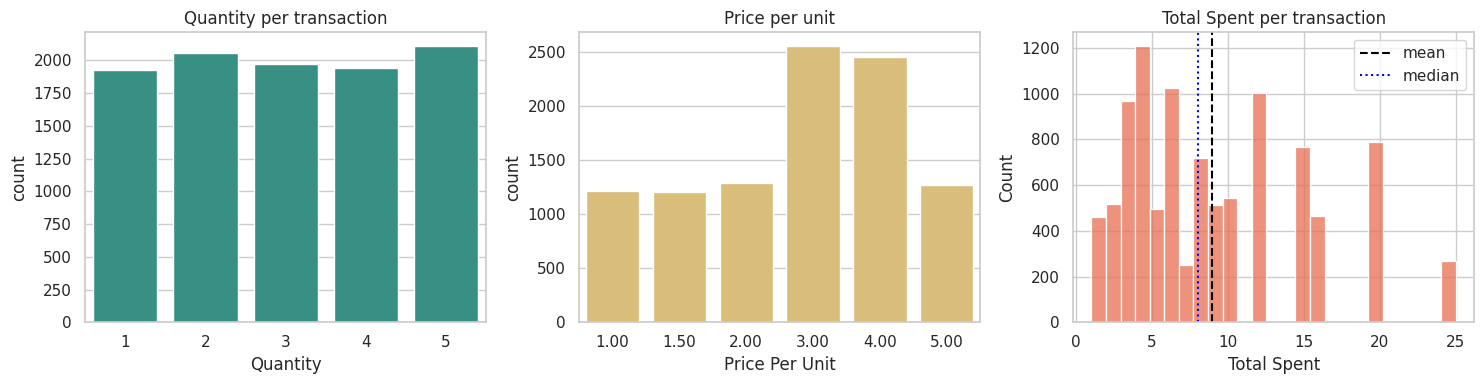

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x="Quantity", data=df, color="#2a9d8f", ax=axes[0])
axes[0].set_title("Quantity per transaction")
sns.countplot(x=df["Price Per Unit"].dropna().map("{:.2f}".format), order=sorted(df["Price Per Unit"].dropna().map("{:.2f}".format).unique(), key=float),
              color="#e9c46a", ax=axes[1])
axes[1].set_title("Price per unit"); axes[1].set_xlabel("Price Per Unit")
sns.histplot(df["Total Spent"].dropna(), bins=25, color="#e76f51", ax=axes[2])
axes[2].axvline(df["Total Spent"].mean(), color="black", ls="--", label="mean")
axes[2].axvline(df["Total Spent"].median(), color="blue", ls=":", label="median")
axes[2].legend(); axes[2].set_title("Total Spent per transaction")
save_fig("01_distributions")
plt.show()

## Step 5: Outliers (noise vs signal)
Two methods from the deck:
- **IQR method:** outlier if below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`. Robust, good for messy business data.
- **Z-score method:** outlier if `|z| > 3`. Sensitive to extreme values, best for normal distributions.

Then the key question: is each outlier **noise** (an error to fix) or **signal** (something real to investigate)?

In [10]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in NUM_COLS:
    s = df[c].dropna()
    lo, hi = iqr_bounds(s)
    z = (s - s.mean()) / s.std()
    rows.append({
        "column": c,
        "IQR lower bound": lo, "IQR upper bound": hi,
        "IQR outliers": int(((s < lo) | (s > hi)).sum()),
        "Z-score outliers (|z|>3)": int((z.abs() > 3).sum()),
        "max value": s.max(),
    })
outlier_tbl = pd.DataFrame(rows).set_index("column")
outlier_tbl

,IQR lower bound,IQR upper bound,IQR outliers,Z-score outliers (|z|>3),max value
column,,,,,
Quantity,-1.00,7.00,0,0,5.00
Price Per Unit,-1.00,7.00,0,0,5.00
Total Spent,-8.00,24.00,269,0,25.00


In [11]:
# Investigate what the IQR method flagged in Total Spent
lo, hi = iqr_bounds(df["Total Spent"].dropna())
flagged = df[df["Total Spent"] > hi]
print(f"IQR upper bound: {hi:.2f} | flagged rows: {len(flagged)}")
print("\nValues flagged:", sorted(flagged["Total Spent"].unique()))
print("\nItems behind the flagged rows:"); print(flagged["Item"].value_counts().to_string())
print("\nQuantity of flagged rows:"); print(flagged["Quantity"].value_counts().to_string())

IQR upper bound: 24.00 | flagged rows: 269

Values flagged: [np.float64(25.0)]

Items behind the flagged rows:
Item
Salad      268
Unknown      1

Quantity of flagged rows:
Quantity
5    268
3      1


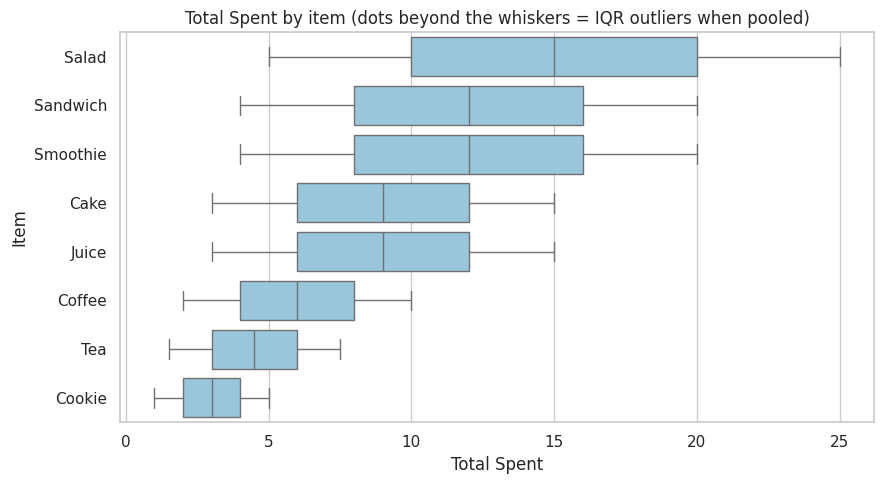

In [12]:
order = known_item.groupby("Item")["Total Spent"].median().sort_values(ascending=False).index
plt.figure(figsize=(9, 5))
sns.boxplot(data=known_item, y="Item", x="Total Spent", order=order, color="#8ecae6", fliersize=2)
plt.title("Total Spent by item (dots beyond the whiskers = IQR outliers when pooled)")
save_fig("02_boxplot_total_by_item")
plt.show()

**Decision.** Compare the two methods: the IQR rule flags a block of high-value orders because the pooled Total Spent column is right-skewed, while the Z-score rule flags none. Inspecting the flagged rows shows they are not errors: nearly all are the largest possible order (5 x the most expensive item, Salad), and every item's price is fixed. This is **signal, not noise**, so nothing is removed. The right reading is "a group of big orders", not "bad data". The one exception in the output above is a record whose item is unknown and whose quantity was filled with the median in Project 1; it is the only flagged row that is a data-quality artifact rather than a real big order, and it is worth noting in your write-up.

## Step 6: Categories (items, location, payment method)
### 6a. Items: popularity vs revenue

In [13]:
item_summary = known_item.groupby("Item").agg(
    transactions=("Transaction ID", "count"),
    units_sold=("Quantity", "sum"),
    unit_price=("Price Per Unit", "median"),
    revenue=("Total Spent", "sum"),
    avg_order_value=("Total Spent", "mean"),
).sort_values("revenue", ascending=False)
item_summary["revenue_share_%"] = item_summary["revenue"] / item_summary["revenue"].sum() * 100
item_summary

,transactions,units_sold,unit_price,revenue,avg_order_value,revenue_share_%
Item,,,,,,
Salad,1272,3825,5.00,"19,125.00",15.04,22.73
Sandwich,1131,3441,4.00,"13,764.00",12.17,16.36
Smoothie,1096,3342,4.00,"13,368.00",12.20,15.89
Juice,1171,3514,3.00,"10,542.00",9.00,12.53
Cake,1139,3471,3.00,"10,413.00",9.14,12.38
Coffee,1291,3919,2.00,"7,838.00",6.07,9.32
Tea,1207,3653,1.50,"5,479.50",4.54,6.51
Cookie,1213,3604,1.00,"3,604.00",2.97,4.28


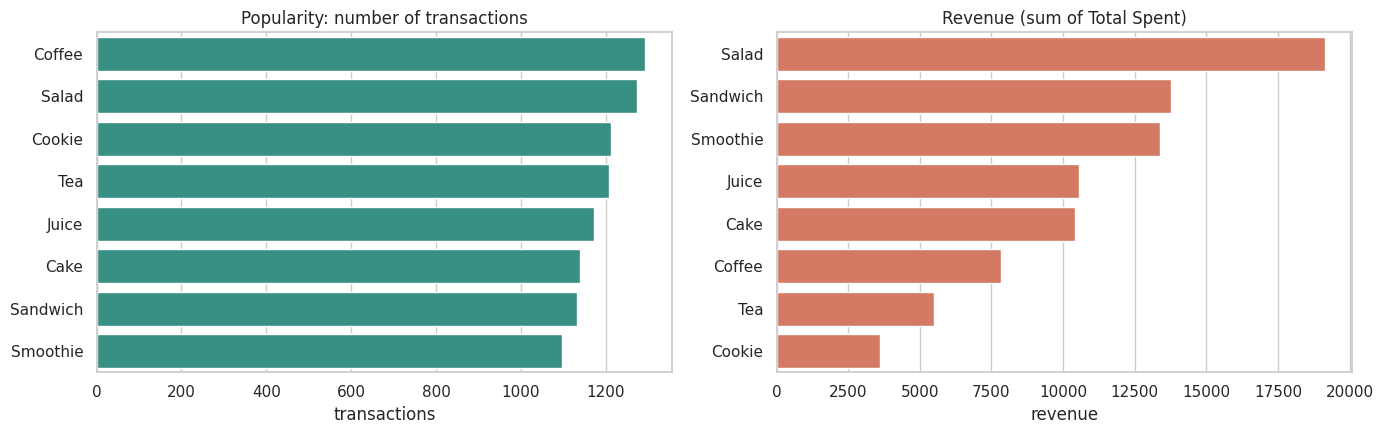

Correlation across items:
  transactions vs revenue: -0.11
  unit price   vs revenue: 0.99


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
t = item_summary.sort_values("transactions", ascending=False)
sns.barplot(x=t["transactions"], y=t.index, color="#2a9d8f", ax=axes[0])
axes[0].set_title("Popularity: number of transactions"); axes[0].set_ylabel("")
r = item_summary.sort_values("revenue", ascending=False)
sns.barplot(x=r["revenue"], y=r.index, color="#e76f51", ax=axes[1])
axes[1].set_title("Revenue (sum of Total Spent)"); axes[1].set_ylabel("")
save_fig("03_items_popularity_vs_revenue")
plt.show()

print("Correlation across items:")
print(f"  transactions vs revenue: {item_summary['transactions'].corr(item_summary['revenue']):.2f}")
print(f"  unit price   vs revenue: {item_summary['unit_price'].corr(item_summary['revenue']):.2f}")

### 6b. In-store vs takeaway
Only rows with a known location are compared (about 40% of rows have an unknown location, so treat conclusions as indicative). Total Spent is right-skewed, so we use a **Mann-Whitney U test** (no normality assumption) as well as the means.

,transactions,mean,median,total
Location,,,,
In-Store,3016,9.04,8.00,"27,250.50"
Takeaway,3022,8.81,7.50,"26,612.50"


Mann-Whitney U p-value (In-Store vs Takeaway): 0.143


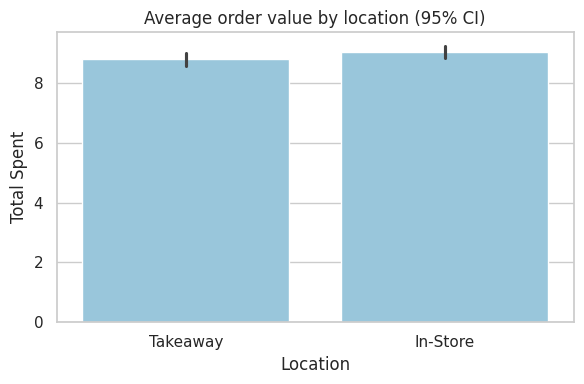

In [15]:
loc = known_loc.groupby("Location")["Total Spent"].agg(
    transactions="count", mean="mean", median="median", total="sum")
display(loc)

a = known_loc.loc[known_loc["Location"] == "In-Store", "Total Spent"].dropna()
b = known_loc.loc[known_loc["Location"] == "Takeaway", "Total Spent"].dropna()
u, p_loc = stats.mannwhitneyu(a, b, alternative="two-sided")
print(f"Mann-Whitney U p-value (In-Store vs Takeaway): {p_loc:.3f}")

plt.figure(figsize=(6, 4))
sns.barplot(data=known_loc, x="Location", y="Total Spent", estimator="mean", errorbar=("ci", 95), color="#8ecae6")
plt.title("Average order value by location (95% CI)")
save_fig("04_location_aov")
plt.show()

### 6c. Payment method

In [16]:
pay = known_pay.groupby("Payment Method")["Total Spent"].agg(
    transactions="count", mean="mean", median="median", total="sum")
pay["share_of_transactions_%"] = pay["transactions"] / pay["transactions"].sum() * 100
display(pay)

groups = [g["Total Spent"].dropna() for _, g in known_pay.groupby("Payment Method")]
h, p_pay = stats.kruskal(*groups)
print(f"Kruskal-Wallis p-value across payment methods: {p_pay:.3f}")

,transactions,mean,median,total,share_of_transactions_%
Payment Method,,,,,
Cash,2258,9.05,8.00,"20,441.50",33.10
Credit Card,2272,9.02,8.00,"20,490.00",33.31
Digital Wallet,2291,8.93,8.00,"20,454.50",33.59


Kruskal-Wallis p-value across payment methods: 0.767


## Step 7: Trends over time
Only rows with a valid date are used. Months have different lengths, so we compare **revenue per day** rather than raw monthly totals (otherwise February looks weak just because it is shorter).

In [17]:
monthly = dated.set_index("Transaction Date").resample("MS").agg(
    transactions=("Transaction ID", "count"),
    revenue=("Total Spent", "sum"))
monthly["days"] = monthly.index.days_in_month
monthly["revenue_per_day"] = monthly["revenue"] / monthly["days"]
monthly["transactions_per_day"] = monthly["transactions"] / monthly["days"]
monthly.index = monthly.index.strftime("%b")
monthly

,transactions,revenue,days,revenue_per_day,transactions_per_day
Transaction Date,,,,,
Jan,818,"7,284.00",31,234.97,26.39
Feb,727,"6,644.00",28,237.29,25.96
Mar,827,"7,225.00",31,233.06,26.68
Apr,774,"7,203.00",30,240.10,25.80
May,777,"7,011.50",31,226.18,25.06
Jun,818,"7,359.00",30,245.30,27.27
Jul,791,"6,885.00",31,222.10,25.52
Aug,803,"7,115.50",31,229.53,25.90
Sep,788,"6,889.00",30,229.63,26.27


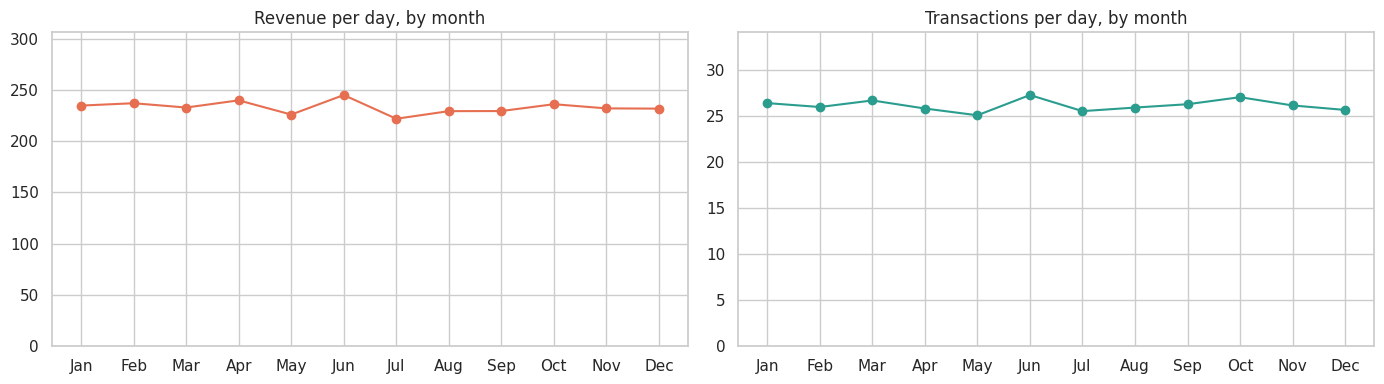

Monthly revenue-per-day variation (coefficient of variation): 2.7%
Peak month: Jun | Lowest month: Jul


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(monthly.index, monthly["revenue_per_day"], marker="o", color="#e76f51")
axes[0].set_title("Revenue per day, by month"); axes[0].set_ylim(0, monthly["revenue_per_day"].max() * 1.25)
axes[1].plot(monthly.index, monthly["transactions_per_day"], marker="o", color="#2a9d8f")
axes[1].set_title("Transactions per day, by month"); axes[1].set_ylim(0, monthly["transactions_per_day"].max() * 1.25)
save_fig("05_monthly_trend")
plt.show()

cv = monthly["revenue_per_day"].std() / monthly["revenue_per_day"].mean()
print(f"Monthly revenue-per-day variation (coefficient of variation): {cv:.1%}")
print(f"Peak month: {monthly['revenue_per_day'].idxmax()} | Lowest month: {monthly['revenue_per_day'].idxmin()}")

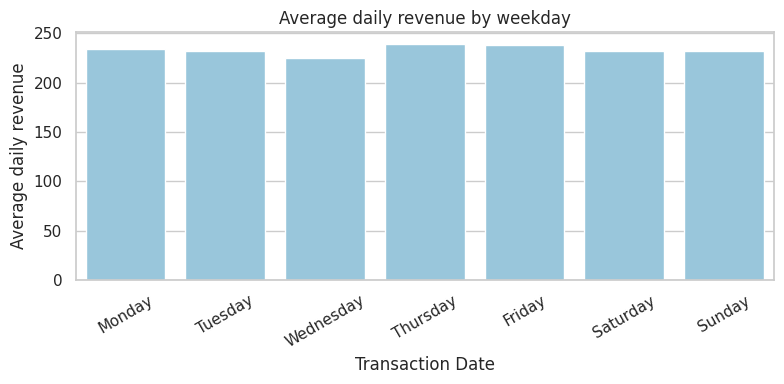

Weekday spread (max / min): 1.06x


In [19]:
# Day-of-week pattern: average daily revenue per weekday
daily = dated.groupby(dated["Transaction Date"].dt.normalize())["Total Spent"].sum()
dow = daily.groupby(daily.index.day_name()).mean()
dow = dow.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])

plt.figure(figsize=(8, 4))
sns.barplot(x=dow.index, y=dow.values, color="#8ecae6")
plt.xticks(rotation=30); plt.ylabel("Average daily revenue"); plt.title("Average daily revenue by weekday")
save_fig("06_weekday_pattern")
plt.show()
print(f"Weekday spread (max / min): {dow.max() / dow.min():.2f}x")

## Step 8: Correlation (mapping relationships)
Pearson's *r* measures the strength and direction of **linear** relationships. Remember the deck's golden rule: **correlation is not causation**. Here there is also a built-in relationship: Total Spent is calculated from Quantity x Price, so strong correlations with it are expected, not discoveries.

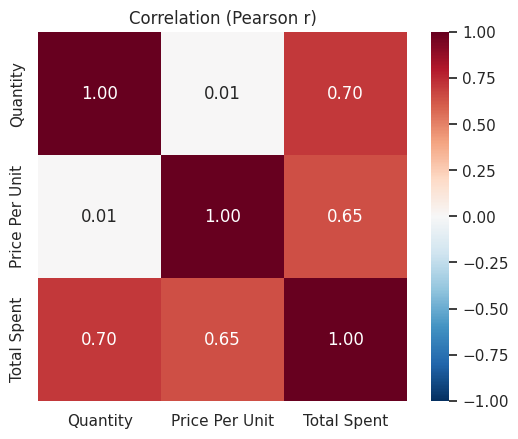

In [20]:
corr = df[NUM_COLS].corr()
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True)
plt.title("Correlation (Pearson r)")
save_fig("07_correlation")
plt.show()

## Step 9: Key observations (the "So what?" test)
This cell builds the findings from the computed numbers above, so the text can't drift from the data. Below it, the observations are translated into plain business language.

In [21]:
total_rev = df["Total Spent"].sum()
top_rev = item_summary["revenue"].idxmax()
top_tx = item_summary["transactions"].idxmax()
low_rev = item_summary["revenue"].idxmin()
tx_range = (item_summary["transactions"].min(), item_summary["transactions"].max())
n_flagged = len(flagged)
n_salad5 = int(((flagged["Item"] == "Salad") & (flagged["Quantity"] == 5)).sum())
n_other = n_flagged - n_salad5

findings = [
 f"1. Scale: {len(df):,} transactions, ${total_rev:,.2f} total revenue, average order ${df['Total Spent'].mean():.2f} (median ${df['Total Spent'].median():.2f}).",
 f"2. Revenue is driven by price, not popularity: {top_rev} earns the most (${item_summary.loc[top_rev,'revenue']:,.0f}, "
 f"{item_summary.loc[top_rev,'revenue_share_%']:.1f}% of known-item revenue), while {top_tx} sells most often. "
 f"Transactions per item are similar ({tx_range[0]:,} to {tx_range[1]:,}); unit price vs revenue correlation across items is "
 f"{item_summary['unit_price'].corr(item_summary['revenue']):.2f}. {low_rev} is the lowest earner.",
 f"3. Total Spent is right-skewed (skewness {df['Total Spent'].skew():.2f}; mean ${df['Total Spent'].mean():.2f} > median ${df['Total Spent'].median():.2f}), "
 f"so the median describes a typical order better than the mean.",
 f"4. Outliers: the IQR rule flags {n_flagged:,} high-value orders; the Z-score rule flags {outlier_tbl.loc['Total Spent','Z-score outliers (|z|>3)']}. "
 f"{n_salad5} of the {n_flagged} are Salad x 5, the largest possible order, so they are valid big orders (signal), not errors. "
 f"The other {n_other} is an incomplete record from Project 1 (item unknown, quantity filled with the median), which is why it is worth flagging for review.",
 f"5. In-store vs takeaway: " + ("no statistically meaningful difference in order value" if p_loc >= 0.05 else "a statistically significant difference in order value")
 + f" (Mann-Whitney p = {p_loc:.2f}; in-store ${loc.loc['In-Store','mean']:.2f} vs takeaway ${loc.loc['Takeaway','mean']:.2f} average).",
 f"6. Payment method: " + ("no meaningful difference in order value across methods" if p_pay >= 0.05 else "order value differs across methods")
 + f" (Kruskal-Wallis p = {p_pay:.2f}).",
 f"7. Time: revenue per day varies by only {cv:.1%} across months (peak {monthly['revenue_per_day'].idxmax()}, low {monthly['revenue_per_day'].idxmin()}) "
 f"and weekdays differ by {dow.max()/dow.min():.2f}x at most, so there is no strong seasonality or weekday effect.",
 f"8. Data caveats: {df['Transaction Date'].isna().sum()} rows lack a date (excluded from trends); "
 f"{(df['Location']=='Unknown').mean():.0%} of locations and {(df['Payment Method']=='Unknown').mean():.0%} of payment methods are unknown; "
 f"{(df['Item']=='Unknown').sum()} transactions have an unknown item (excluded from item comparisons).",
]
print("\n\n".join(findings))

1. Scale: 10,000 transactions, $89,274.50 total revenue, average order $8.93 (median $8.00).

2. Revenue is driven by price, not popularity: Salad earns the most ($19,125, 22.7% of known-item revenue), while Coffee sells most often. Transactions per item are similar (1,096 to 1,291); unit price vs revenue correlation across items is 0.99. Cookie is the lowest earner.

3. Total Spent is right-skewed (skewness 0.82; mean $8.93 > median $8.00), so the median describes a typical order better than the mean.

4. Outliers: the IQR rule flags 269 high-value orders; the Z-score rule flags 0. 268 of the 269 are Salad x 5, the largest possible order, so they are valid big orders (signal), not errors. The other 1 is an incomplete record from Project 1 (item unknown, quantity filled with the median), which is why it is worth flagging for review.

5. In-store vs takeaway: no statistically meaningful difference in order value (Mann-Whitney p = 0.14; in-store $9.04 vs takeaway $8.81 average).

6. Paym

### In plain business language
- **Promote by price, not popularity.** Every item sells at a similar rate, so revenue differences come from price. Higher-priced items matter most to revenue; low-priced items (Cookie, Tea) contribute little even though they sell as often.
- **Treat big orders as normal.** The "outliers" are legitimate large orders, so don't clean them away. If you want to study them, they are the most valuable customers per visit.
- **No strong seasonal or weekday pattern here.** There is nothing to staff or stock differently by month or day based on this data.
- **In-store and takeaway customers behave alike** on order value, though 40% unknown locations limits how firmly this can be stated. Better location capture at the till would sharpen it.
- **Fix the data capture.** Payment method and location are the weakest fields. The biggest analytical gain would come from collecting them properly.

**Honest limitation.** This is a practice dataset with near-uniform patterns, so the real finding is that the business looks stable and price-driven, not that there are hidden problems. In a real business, the next step would be testing promotions or pricing changes, which EDA alone cannot establish (correlation is not causation).

## Step 10: Save outputs for the portfolio

In [22]:
item_summary.to_csv(TAB_DIR / "item_summary.csv")
monthly.to_csv(TAB_DIR / "monthly_trend.csv")
outlier_tbl.to_csv(TAB_DIR / "outlier_summary.csv")
summary.to_csv(TAB_DIR / "descriptive_stats.csv")
(Path("key_observations.txt")).write_text("\n\n".join(findings))
print("Saved: figures/*.png, tables/*.csv, key_observations.txt")

Saved: figures/*.png, tables/*.csv, key_observations.txt
